
# Assignment 04: EEG Signal Processing and Functional Connectivity

## Advanced Computational Neuroscience

In [126]:
%pip install --upgrade matplotlib
%pip install mne-connectivity
%pip install networkx


[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [127]:
from pathlib import Path
import os
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import mne

from scipy.signal import (
    welch,
    csd,
    coherence,
    butter,
    sosfiltfilt,
    hilbert
)

print("MNE version:", mne.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)


MNE version: 1.13.2
NumPy version: 2.5.3
Pandas version: 3.0.6


In [128]:
project_dir = Path.home() / "EEG-Assignment04"
mne_data_dir = project_dir / "MNE-sample-data"

mne_data_dir.mkdir(parents=True, exist_ok=True)

In [129]:
data_path = mne.datasets.sample.data_path(
    path=mne_data_dir
)

print("Dataset location:", data_path)

Dataset location: /Users/fatemeh/EEG-Assignment04/MNE-sample-data/MNE-sample-data


In [130]:
raw_file = (
    data_path
    / "MEG"
    / "sample"
    / "sample_audvis_raw.fif"
)

print("Raw EEG file:", raw_file)
print("File exists:", raw_file.exists())

raw_original = mne.io.read_raw_fif(
    raw_file,
    preload=True
)

Raw EEG file: /Users/fatemeh/EEG-Assignment04/MNE-sample-data/MNE-sample-data/MEG/sample/sample_audvis_raw.fif
File exists: True
Opening raw data file /Users/fatemeh/EEG-Assignment04/MNE-sample-data/MNE-sample-data/MEG/sample/sample_audvis_raw.fif...
    Read a total of 3 projection items:
        PCA-v1 (1 x 102)  idle
        PCA-v2 (1 x 102)  idle
        PCA-v3 (1 x 102)  idle
    Range : 25800 ... 192599 =     42.956 ...   320.670 secs
Ready.
Reading 0 ... 166799  =      0.000 ...   277.714 secs...


In [131]:
raw_original = mne.io.read_raw_fif(
    raw_file,
    preload=True
)

print(raw_original)


Opening raw data file /Users/fatemeh/EEG-Assignment04/MNE-sample-data/MNE-sample-data/MEG/sample/sample_audvis_raw.fif...
    Read a total of 3 projection items:
        PCA-v1 (1 x 102)  idle
        PCA-v2 (1 x 102)  idle
        PCA-v3 (1 x 102)  idle
    Range : 25800 ... 192599 =     42.956 ...   320.670 secs
Ready.
Reading 0 ... 166799  =      0.000 ...   277.714 secs...
<Raw | sample_audvis_raw.fif, 376 x 166800 (277.7 s), ~481.7 MiB, data loaded>


In [132]:
print("Sampling frequency:", raw_original.info["sfreq"], "Hz")

print("Number of channels:", len(raw_original.ch_names))

print("Recording duration:", 
      raw_original.n_times / raw_original.info["sfreq"], 
      "seconds")

print("\nChannel types:")
print(Counter(raw_original.get_channel_types()))


Sampling frequency: 600.614990234375 Hz
Number of channels: 376
Recording duration: 277.7153462901591 seconds

Channel types:
Counter({'grad': 204, 'mag': 102, 'eeg': 60, 'stim': 9, 'eog': 1})


In [133]:
raw = raw_original.copy()

raw.pick(["eeg", "eog", "stim"])

print("Number of selected channels:", len(raw.ch_names))

print("\nSelected channel types:")
print(Counter(raw.get_channel_types()))

for i, channel in enumerate(raw.ch_names, start=1):
    print(i, channel)


Number of selected channels: 70

Selected channel types:
Counter({'eeg': 60, 'stim': 9, 'eog': 1})
1 STI 001
2 STI 002
3 STI 003
4 STI 004
5 STI 005
6 STI 006
7 STI 014
8 STI 015
9 STI 016
10 EEG 001
11 EEG 002
12 EEG 003
13 EEG 004
14 EEG 005
15 EEG 006
16 EEG 007
17 EEG 008
18 EEG 009
19 EEG 010
20 EEG 011
21 EEG 012
22 EEG 013
23 EEG 014
24 EEG 015
25 EEG 016
26 EEG 017
27 EEG 018
28 EEG 019
29 EEG 020
30 EEG 021
31 EEG 022
32 EEG 023
33 EEG 024
34 EEG 025
35 EEG 026
36 EEG 027
37 EEG 028
38 EEG 029
39 EEG 030
40 EEG 031
41 EEG 032
42 EEG 033
43 EEG 034
44 EEG 035
45 EEG 036
46 EEG 037
47 EEG 038
48 EEG 039
49 EEG 040
50 EEG 041
51 EEG 042
52 EEG 043
53 EEG 044
54 EEG 045
55 EEG 046
56 EEG 047
57 EEG 048
58 EEG 049
59 EEG 050
60 EEG 051
61 EEG 052
62 EEG 053
63 EEG 054
64 EEG 055
65 EEG 056
66 EEG 057
67 EEG 058
68 EEG 059
69 EEG 060
70 EOG 061


In [134]:
print("Bad channels:", raw.info["bads"])

print("Number of bad channels:", len(raw.info["bads"]))

Bad channels: ['EEG 053']
Number of bad channels: 1


In [135]:
eeg_picks = mne.pick_types(
    raw.info,
    eeg=True,
    eog=False,
    stim=False,
    exclude=[]
)

print("Number of EEG channels:", len(eeg_picks))

Number of EEG channels: 60


In [137]:
eeg_names = [raw.ch_names[i] for i in eeg_picks]

eeg_positions = np.array([
    raw.info["chs"][i]["loc"][:3]
    for i in eeg_picks
])

electrode_table = pd.DataFrame(
    eeg_positions,
    columns=["X", "Y", "Z"]
)

electrode_table.insert(0, "Channel", eeg_names)

electrode_table["Bad"] = [
    name in raw.info["bads"]
    for name in eeg_names
]

print("Number of EEG channels:", len(eeg_names))
print("Table shape:", electrode_table.shape)

display(electrode_table)

Number of EEG channels: 60
Table shape: (60, 5)


,Channel,X,Y,Z,Bad
0,EEG 001,-0.037370,0.105680,0.073339,False
1,EEG 002,-0.014913,0.110798,0.076501,False
2,EEG 003,0.012126,0.109593,0.077361,False
3,EEG 004,-0.065725,0.078176,0.065463,False
4,EEG 005,-0.050630,0.084452,0.088301,False
5,EEG 006,0.025338,0.089109,0.099804,False
6,EEG 007,0.043539,0.091466,0.076064,False
7,EEG 008,-0.077854,0.057435,0.056995,False
8,EEG 009,-0.070748,0.059378,0.083787,False
9,EEG 010,-0.058895,0.064041,0.101221,False


In [140]:
eeg_channels = [
    ch for ch in raw_original.info["chs"]
    if ch["ch_name"].startswith("EEG")
]

for ch in eeg_channels[:5]:
    print(ch["ch_name"], ch["loc"][:3])

EEG 001 [-0.03737009  0.10568011  0.07333875]
EEG 002 [-0.01491282  0.11079782  0.07650087]
EEG 003 [0.01212589 0.10959283 0.07736051]
EEG 004 [-0.06572473  0.0781765   0.06546284]
EEG 005 [-0.0506296   0.08445242  0.08830147]


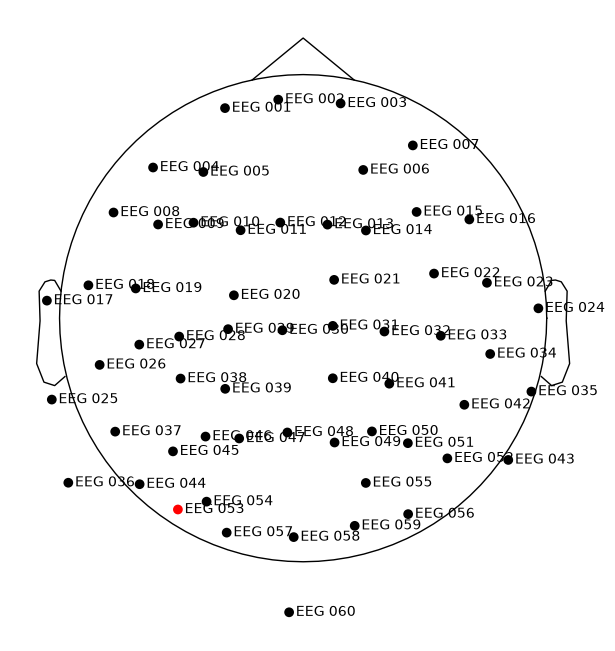

In [141]:
fig = raw.plot_sensors(
    ch_type="eeg",
    kind="topomap",
    show_names=True,
    show=False
)

plt.show()

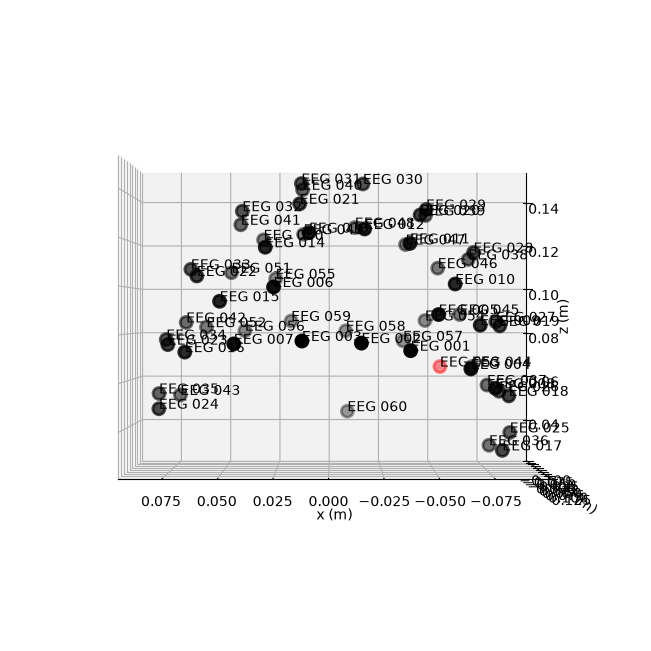

In [142]:
fig = raw.plot_sensors(
    ch_type="eeg",
    kind="3d",
    show_names=True,
    show=False
)

plt.show()

In [143]:
raw_preproc = raw.copy()

print(raw_preproc)

<Raw | sample_audvis_raw.fif, 70 x 166800 (277.7 s), ~92.0 MiB, data loaded>


In [144]:
raw_preproc.notch_filter(
    freqs=[60],
    picks="eeg",
    phase="zero"
)

print("60 Hz Notch filtering completed.")

Filtering raw data in 1 contiguous segment
Setting up band-stop filter from 59 - 61 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 59.35
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 59.10 Hz)
- Upper passband edge: 60.65 Hz
- Upper transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 60.90 Hz)
- Filter length: 3965 samples (6.602 s)

60 Hz Notch filtering completed.


In [145]:
raw_preproc.filter(
    l_freq=0.1,
    h_freq=40,
    picks="eeg",
    method="fir",
    phase="zero",
    fir_design="firwin"
)

print("0.1–40 Hz Band-pass filtering completed.")

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.10
- Lower transition bandwidth: 0.10 Hz (-6 dB cutoff frequency: 0.05 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 19821 samples (33.001 s)

0.1–40 Hz Band-pass filtering completed.


In [146]:
raw_preproc.set_eeg_reference(
    ref_channels="average",
    projection=False
)
print("Average reference applied successfully.")

EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.
Average reference applied successfully.


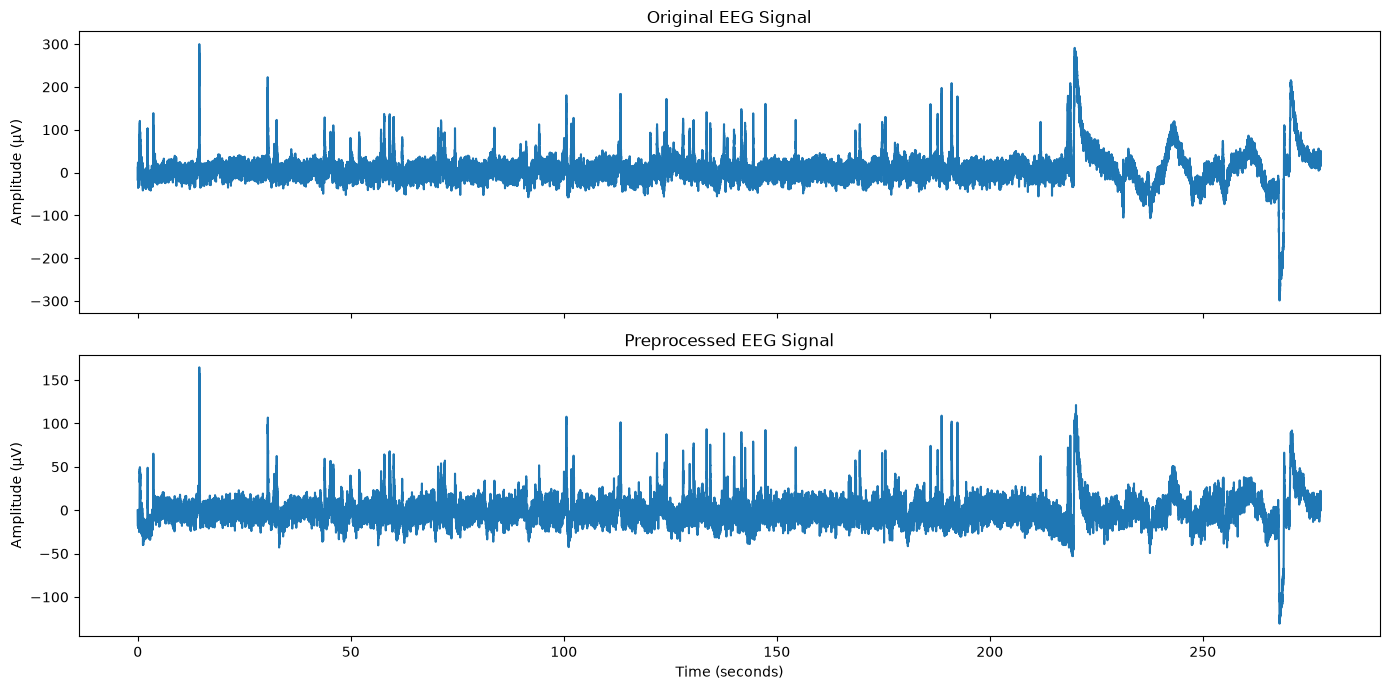

In [147]:
channel_name = "EEG 001"

original_data = raw.get_data(
    picks=[channel_name]
)[0]

processed_data = raw_preproc.get_data(
    picks=[channel_name]
)[0]

sfreq = raw.info["sfreq"]

time = np.arange(
    len(original_data)
) / sfreq

fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 7),
    sharex=True
)

axes[0].plot(
    time,
    original_data * 1e6
)

axes[0].set_title(
    "Original EEG Signal"
)

axes[0].set_ylabel(
    "Amplitude (µV)"
)

axes[1].plot(
    time,
    processed_data * 1e6
)

axes[1].set_title(
    "Preprocessed EEG Signal"
)

axes[1].set_ylabel(
    "Amplitude (µV)"
)

axes[1].set_xlabel(
    "Time (seconds)"
)

plt.tight_layout()
plt.show()

In [148]:
channel_name = "EEG 001"

original_data = raw.get_data(
    picks=[channel_name]
)[0]

processed_data = raw_preproc.get_data(
    picks=[channel_name]
)[0]

freq_original, psd_original = welch(
    original_data,
    fs=sfreq,
    nperseg=int(sfreq * 2),
    noverlap=int(sfreq * 1)
)

freq_processed, psd_processed = welch(
    processed_data,
    fs=sfreq,
    nperseg=int(sfreq * 2),
    noverlap=int(sfreq * 1)
)

print("Welch PSD calculation completed.")
print("Frequency resolution:", freq_original[1] - freq_original[0], "Hz")

Welch PSD calculation completed.
Frequency resolution: 0.5000957454074729 Hz


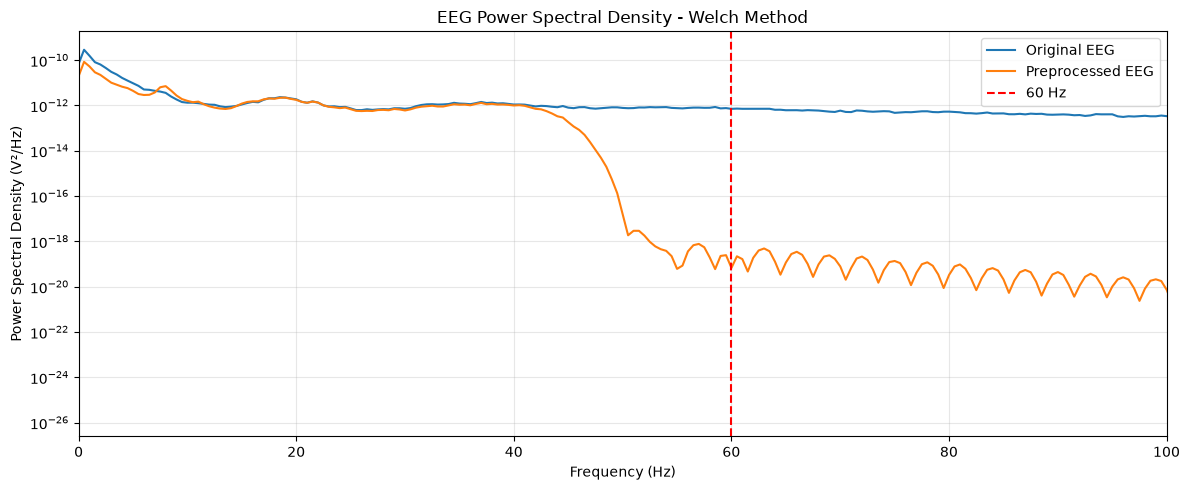

In [149]:
plt.figure(figsize=(12, 5))

plt.semilogy(
    freq_original,
    psd_original,
    label="Original EEG"
)

plt.semilogy(
    freq_processed,
    psd_processed,
    label="Preprocessed EEG"
)

plt.axvline(
    60,
    color="red",
    linestyle="--",
    label="60 Hz"
)

plt.xlim(0, 100)

plt.xlabel("Frequency (Hz)")
plt.ylabel("Power Spectral Density (V²/Hz)")
plt.title("EEG Power Spectral Density - Welch Method")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

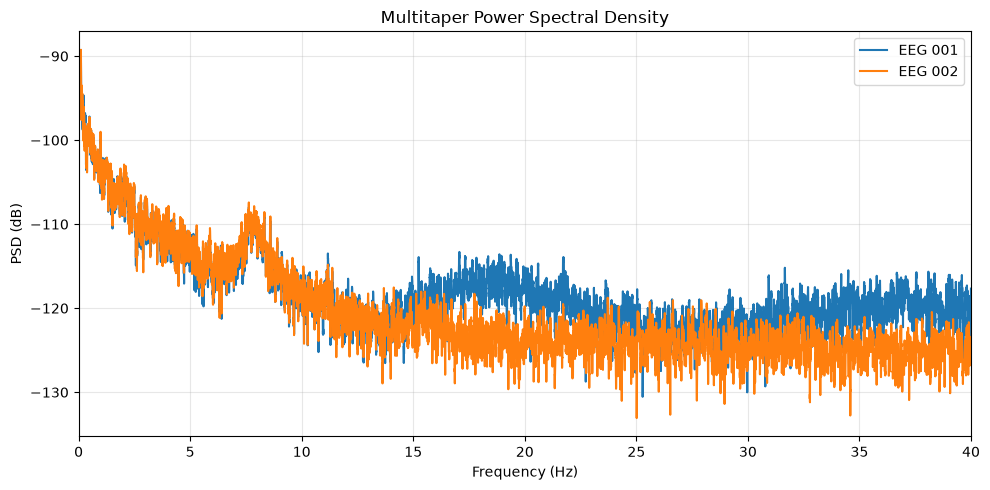

In [150]:
psd_mt, freqs_mt = mne.time_frequency.psd_array_multitaper(
    selected_data,
    sfreq=sfreq,
    fmin=0.1,
    fmax=40,
    bandwidth=None,
    adaptive=False,
    normalization="full",
    verbose=False
)

plt.figure(figsize=(10, 5))

for i, channel in enumerate(selected_channels):
    plt.plot(
        freqs_mt,
        10 * np.log10(psd_mt[i]),
        label=channel
    )

plt.xlabel("Frequency (Hz)")
plt.ylabel("PSD (dB)")
plt.title("Multitaper Power Spectral Density")
plt.xlim(0, 40)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [152]:
selected_channels = ["EEG 001", "EEG 002"]

selected_data = raw_preproc.get_data(
    picks=selected_channels
)

print("Selected data shape:", selected_data.shape)
print("Selected channels:", selected_channels)

Selected data shape: (2, 166800)
Selected channels: ['EEG 001', 'EEG 002']


In [153]:
freqs_csd, csd_xy = csd(
    selected_data[0],
    selected_data[1],
    fs=sfreq,
    nperseg=int(sfreq * 2),
    noverlap=int(sfreq * 1)
)

print("CSD shape:", csd_xy.shape)
print("Frequency resolution:", freqs_csd[1] - freqs_csd[0], "Hz")

CSD shape: (601,)
Frequency resolution: 0.5000957454074729 Hz


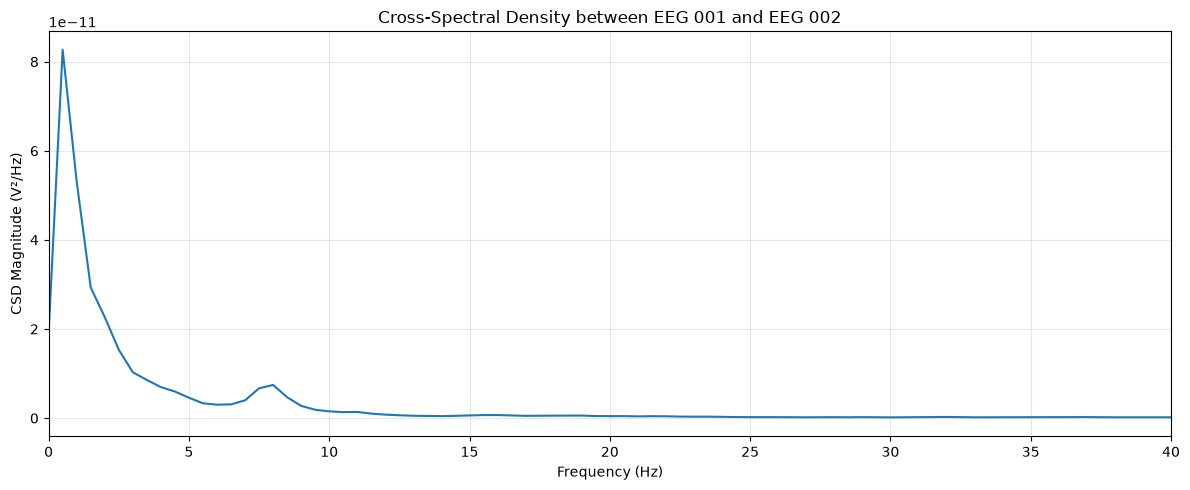

In [154]:
csd_magnitude = np.abs(csd_xy)

plt.figure(figsize=(12, 5))

plt.plot(freqs_csd, csd_magnitude)

plt.xlabel("Frequency (Hz)")
plt.ylabel("CSD Magnitude (V²/Hz)")
plt.title("Cross-Spectral Density between EEG 001 and EEG 002")

plt.xlim(0, 40)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

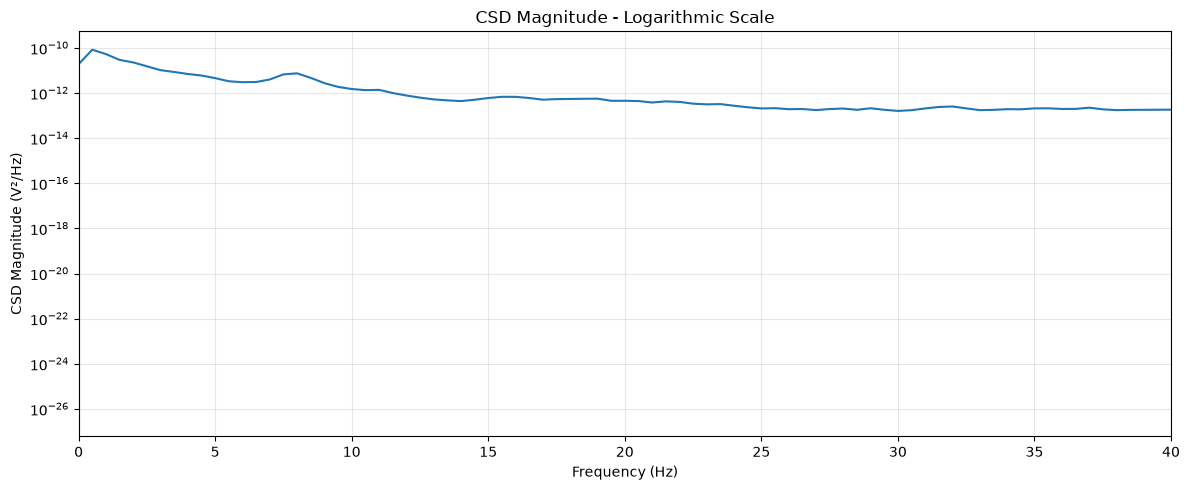

In [155]:
plt.figure(figsize=(12, 5))

plt.semilogy(freqs_csd, csd_magnitude)

plt.xlabel("Frequency (Hz)")
plt.ylabel("CSD Magnitude (V²/Hz)")
plt.title("CSD Magnitude - Logarithmic Scale")

plt.xlim(0, 40)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [156]:
freqs_coh, coherence_xy = coherence(
    selected_data[0],
    selected_data[1],
    fs=sfreq,
    nperseg=int(sfreq * 2),
    noverlap=int(sfreq * 1)
)

print("Coherence shape:", coherence_xy.shape)
print("Minimum coherence:", np.min(coherence_xy))
print("Maximum coherence:", np.max(coherence_xy))

Coherence shape: (601,)
Minimum coherence: 0.02681347933520633
Maximum coherence: 0.9815750712995099


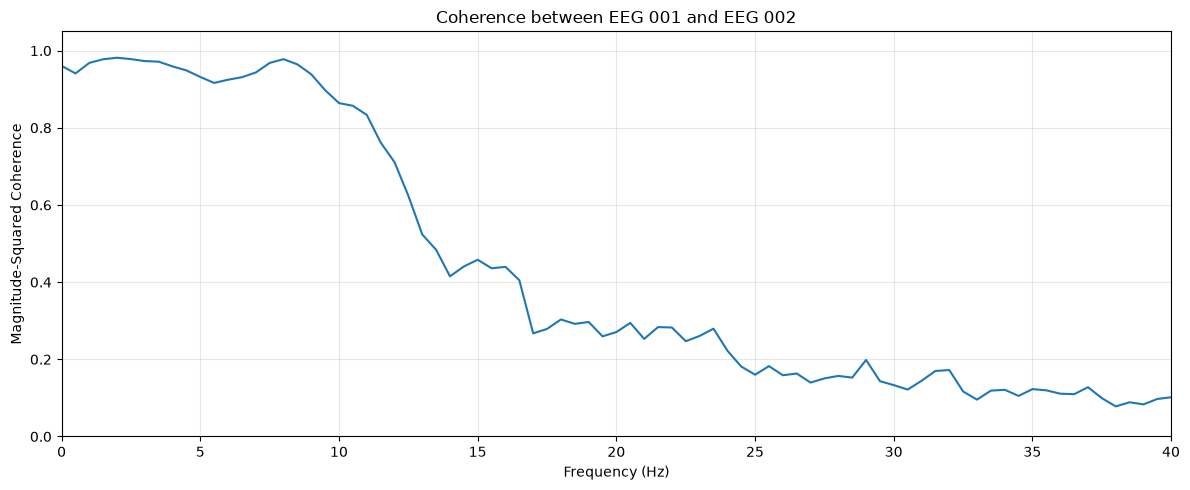

In [157]:
plt.figure(figsize=(12, 5))

plt.plot(freqs_coh, coherence_xy)

plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude-Squared Coherence")
plt.title("Coherence between EEG 001 and EEG 002")

plt.xlim(0, 40)
plt.ylim(0, 1.05)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [161]:
def band_mean(freqs, values, fmin, fmax):
    mask = (freqs >= fmin) & (freqs <= fmax)
    return np.mean(values[mask])

In [162]:
bands = {
    "Delta": (1, 4),
    "Theta": (4, 8),
    "Alpha": (8, 13),
    "Beta": (14, 30)
}

for band_name, (fmin, fmax) in bands.items():
    mean_coh = band_mean(freqs_coh, coherence_xy, fmin, fmax)
    print(f"{band_name}: {mean_coh:.4f}")

Delta: 0.9750
Theta: 0.9404
Alpha: 0.8430
Beta: 0.2648


In [163]:
good_eeg_picks = mne.pick_types(
    raw_preproc.info,
    eeg=True,
    exclude="bads"
)

eeg_data_all = raw_preproc.get_data(picks=good_eeg_picks)

eeg_names_all = [
    raw_preproc.ch_names[i] for i in good_eeg_picks
]

n_channels = len(eeg_names_all)

print("Number of good EEG channels:", n_channels)
print("Data shape:", eeg_data_all.shape)

Number of good EEG channels: 59
Data shape: (59, 166800)


In [164]:
coherence_matrix_welch = np.zeros((n_channels, n_channels))

for i in range(n_channels):
    coherence_matrix_welch[i, i] = 1.0

    for j in range(i + 1, n_channels):
        freqs, coh = coherence(
            eeg_data_all[i],
            eeg_data_all[j],
            fs=sfreq,
            nperseg=int(sfreq * 2),
            noverlap=int(sfreq * 1)
        )

        mean_coh = band_mean(freqs, coh, 14, 30)

        coherence_matrix_welch[i, j] = mean_coh
        coherence_matrix_welch[j, i] = mean_coh

print("Matrix shape:", coherence_matrix_welch.shape)
print("Minimum:", coherence_matrix_welch.min())
print("Maximum:", coherence_matrix_welch.max())

Matrix shape: (59, 59)
Minimum: 0.003934715052358448
Maximum: 1.0


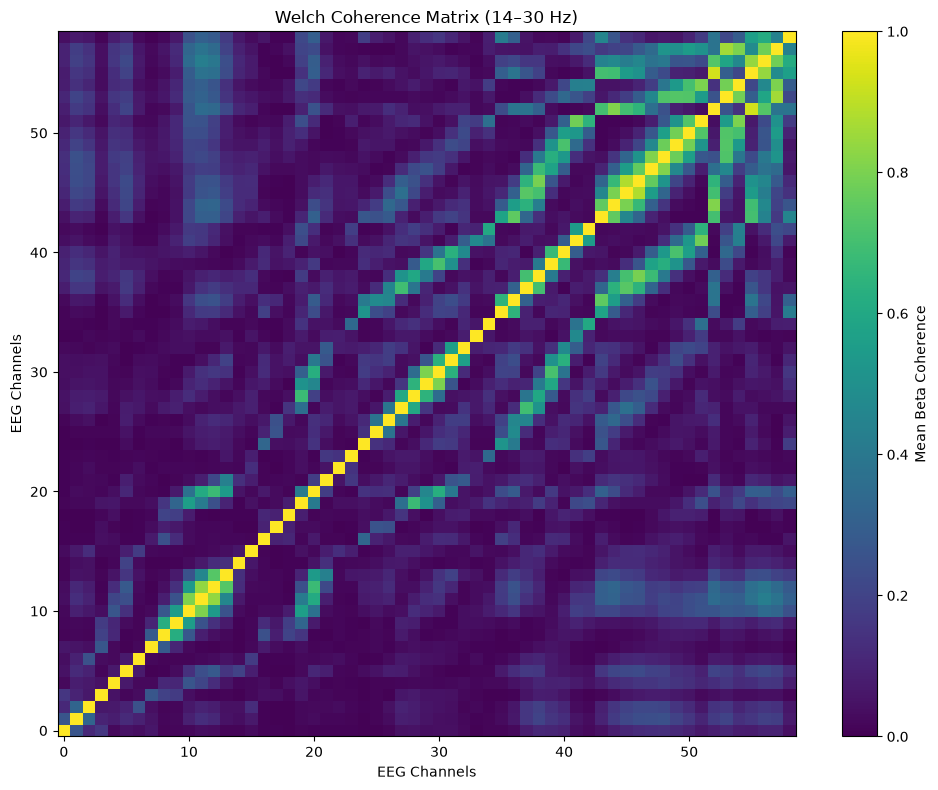

In [165]:
plt.figure(figsize=(10, 8))

plt.imshow(
    coherence_matrix_welch,
    cmap="viridis",
    vmin=0,
    vmax=1,
    origin="lower",
    aspect="auto"
)

plt.colorbar(label="Mean Beta Coherence")
plt.xlabel("EEG Channels")
plt.ylabel("EEG Channels")
plt.title("Welch Coherence Matrix (14–30 Hz)")

plt.tight_layout()
plt.show()

In [166]:
raw_eeg = raw_preproc.copy().pick(good_eeg_picks)

epochs = mne.make_fixed_length_epochs(
    raw_eeg,
    duration=2.0,
    overlap=1.0,
    preload=True
)

print("Number of epochs:", len(epochs))
print("Epoch data shape:", epochs.get_data().shape)

Not setting metadata
276 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 276 events and 1201 original time points ...
0 bad epochs dropped
Number of epochs: 276
Epoch data shape: (276, 59, 1201)


In [167]:
from mne_connectivity import spectral_connectivity_epochs

con_mt = spectral_connectivity_epochs(
    epochs,
    method="coh",
    mode="multitaper",
    sfreq=sfreq,
    fmin=14,
    fmax=30,
    faverage=True,
    verbose=False
)

print("Multitaper coherence calculation completed.")
print("Connectivity shape:", con_mt.get_data().shape)

Multitaper coherence calculation completed.
Connectivity shape: (3481, 1)


In [168]:
coherence_matrix_mt = con_mt.get_data(output="dense").squeeze()

print("Multitaper matrix shape:", coherence_matrix_mt.shape)
print("Minimum:", coherence_matrix_mt.min())
print("Maximum:", coherence_matrix_mt.max())

Multitaper matrix shape: (59, 59)
Minimum: 0.0
Maximum: 0.9660815104549024


In [169]:
matrix_before = coherence_matrix_mt.copy()

coherence_matrix_mt = np.maximum(
    coherence_matrix_mt,
    coherence_matrix_mt.T
)

print("Maximum change:",
      np.max(np.abs(coherence_matrix_mt - matrix_before)))

Maximum change: 0.9660815104549024


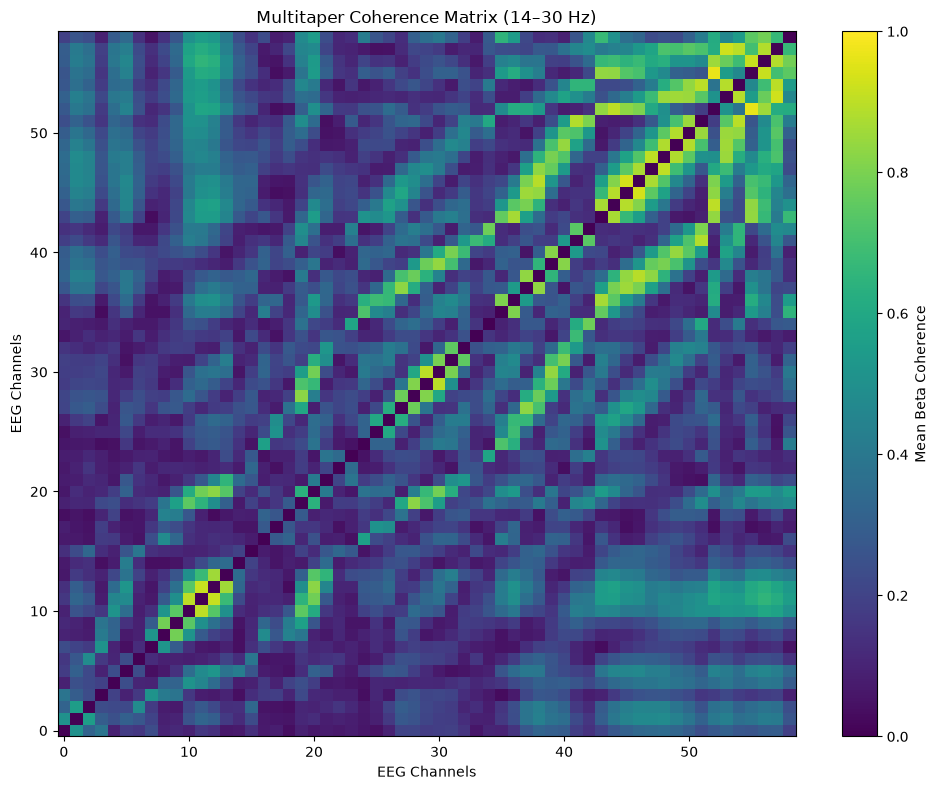

In [170]:
plt.figure(figsize=(10, 8))

plt.imshow(
    coherence_matrix_mt,
    cmap="viridis",
    vmin=0,
    vmax=1,
    origin="lower",
    aspect="auto"
)

plt.colorbar(label="Mean Beta Coherence")
plt.xlabel("EEG Channels")
plt.ylabel("EEG Channels")
plt.title("Multitaper Coherence Matrix (14–30 Hz)")
plt.tight_layout()
plt.show()

In [172]:
upper_indices = np.triu_indices(n_channels, k=1)

welch_values = coherence_matrix_welch[upper_indices]
mt_values = coherence_matrix_mt[upper_indices]

print("Welch Coherence:")
print("Mean:", np.mean(welch_values))
print("Median:", np.median(welch_values))

print("\nMultitaper Coherence:")
print("Mean:", np.mean(mt_values))
print("Median:", np.median(mt_values))

print("\nMean Absolute Difference:")
print(np.mean(np.abs(welch_values - mt_values)))

Welch Coherence:
Mean: 0.12231324360327656
Median: 0.06111504737705208

Multitaper Coherence:
Mean: 0.2796255056954666
Median: 0.22821255107141344

Mean Absolute Difference:
0.15731226209219007


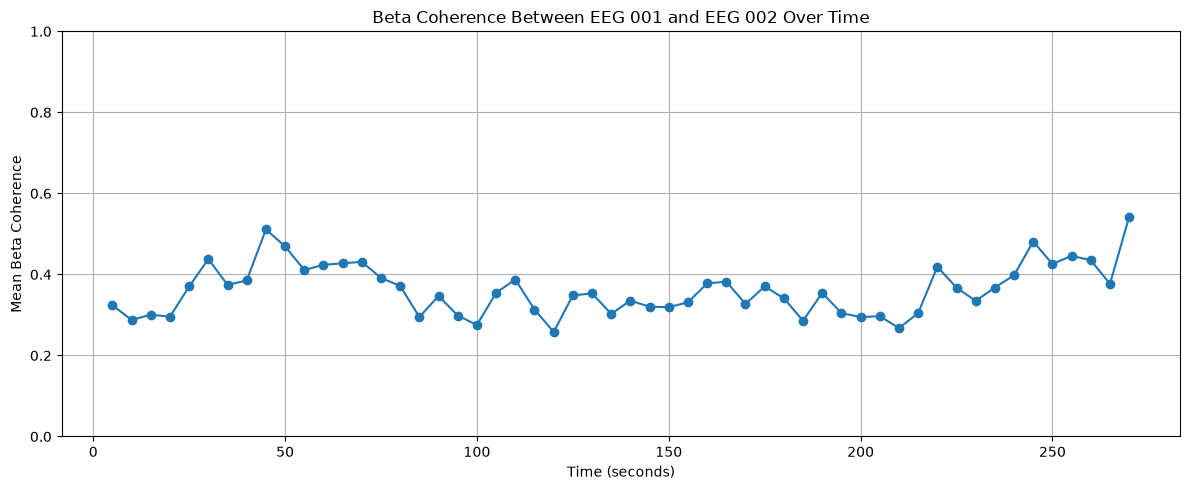

In [173]:
selected_channels = ["EEG 001", "EEG 002"]
pair_data = raw_preproc.get_data(picks=selected_channels)

window_length = int(10 * sfreq) 
step_length = int(5 * sfreq)     

coherence_over_time = []
time_points = []

for start in range(0, pair_data.shape[1] - window_length + 1, step_length):

    end = start + window_length
    data_1 = pair_data[0, start:end]
    data_2 = pair_data[1, start:end]

    freqs, coh = coherence(
        data_1,
        data_2,
        fs=sfreq,
        nperseg=int(2 * sfreq),
        noverlap=int(1 * sfreq)
    )

    beta_coh = band_mean(freqs, coh, 14, 30)
    coherence_over_time.append(beta_coh)

    time_points.append((start + window_length / 2) / sfreq)

plt.figure(figsize=(12, 5))
plt.plot(time_points, coherence_over_time, marker="o")
plt.xlabel("Time (seconds)")
plt.ylabel("Mean Beta Coherence")
plt.title("Beta Coherence Between EEG 001 and EEG 002 Over Time")
plt.ylim(0, 1)
plt.grid(True)
plt.tight_layout()
plt.show()

In [174]:
from scipy.signal import butter, sosfiltfilt

low_cutoff = 14
high_cutoff = 30
filter_order = 4

sos = butter(
    filter_order,
    [low_cutoff, high_cutoff],
    btype="bandpass",
    fs=sfreq,
    output="sos"
)

beta_data = sosfiltfilt(sos, eeg_data_all, axis=1)

print("Beta-filtered data shape:", beta_data.shape)

Beta-filtered data shape: (59, 166800)


In [175]:
from scipy.signal import hilbert

analytic_signals = hilbert(beta_data, axis=1)
phase_data = np.angle(analytic_signals)

print("Phase data shape:", phase_data.shape)
print("Minimum phase:", np.min(phase_data))
print("Maximum phase:", np.max(phase_data))

Phase data shape: (59, 166800)
Minimum phase: -3.141590974906048
Maximum phase: 3.1415919409436164


In [176]:
samples_to_remove = int(sfreq)

phase_data_trimmed = phase_data[
    :, samples_to_remove:-samples_to_remove
]

print("Trimmed phase data shape:", phase_data_trimmed.shape)

Trimmed phase data shape: (59, 165600)


In [177]:
plv_matrix = np.zeros((n_channels, n_channels))

for i in range(n_channels):
    for j in range(i, n_channels):

        phase_difference = (
            phase_data_trimmed[i] - phase_data_trimmed[j]
        )

        plv = np.abs(np.mean(np.exp(1j * phase_difference)))

        plv_matrix[i, j] = plv
        plv_matrix[j, i] = plv

print("PLV matrix shape:", plv_matrix.shape)
print("Minimum PLV:", np.min(plv_matrix))
print("Maximum PLV:", np.max(plv_matrix))

PLV matrix shape: (59, 59)
Minimum PLV: 0.006257679017412027
Maximum PLV: 1.0


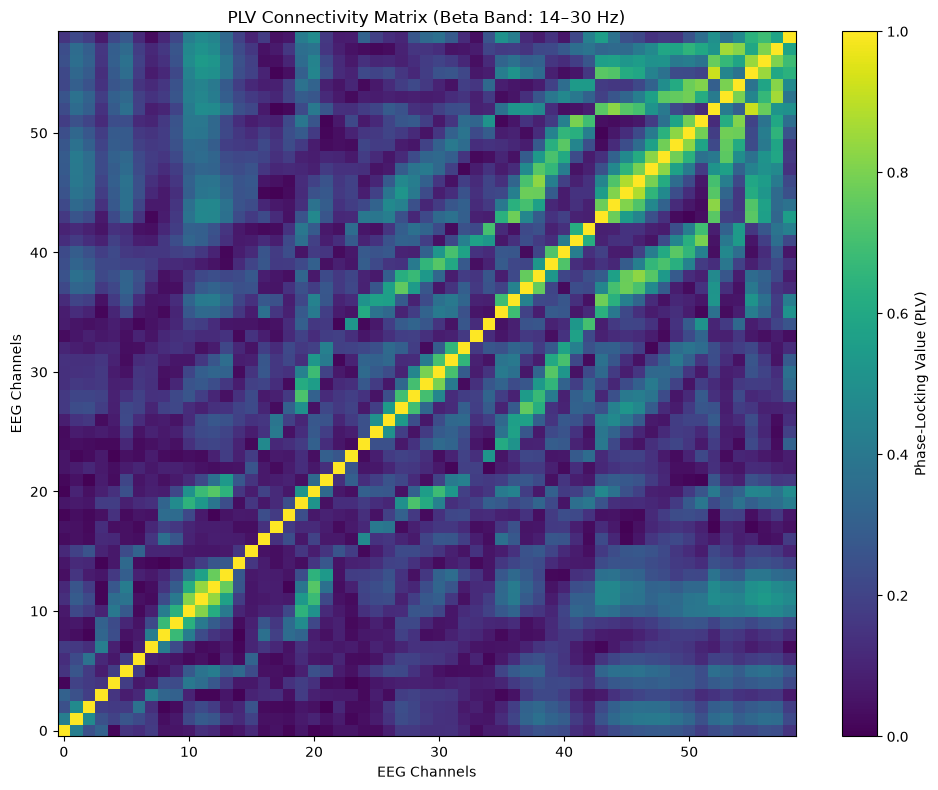

In [178]:
plt.figure(figsize=(10, 8))

plt.imshow(
    plv_matrix,
    cmap="viridis",
    vmin=0,
    vmax=1,
    origin="lower",
    aspect="auto"
)

plt.colorbar(label="Phase-Locking Value (PLV)")
plt.xlabel("EEG Channels")
plt.ylabel("EEG Channels")
plt.title("PLV Connectivity Matrix (Beta Band: 14–30 Hz)")
plt.tight_layout()
plt.show()

In [179]:
amplitude_envelope = np.abs(analytic_signals)

print("Amplitude envelope shape:", amplitude_envelope.shape)
print("Minimum amplitude:", np.min(amplitude_envelope))
print("Maximum amplitude:", np.max(amplitude_envelope))

Amplitude envelope shape: (59, 166800)
Minimum amplitude: 4.483701305441728e-10
Maximum amplitude: 3.958922737006317e-05


In [180]:
amplitude_envelope_trimmed = amplitude_envelope[
    :, samples_to_remove:-samples_to_remove
]

print("Trimmed envelope shape:", amplitude_envelope_trimmed.shape)

Trimmed envelope shape: (59, 165600)


In [181]:
envelope_corr_matrix = np.corrcoef(amplitude_envelope_trimmed)

print("Envelope correlation matrix shape:", envelope_corr_matrix.shape)
print("Minimum correlation:", np.min(envelope_corr_matrix))
print("Maximum correlation:", np.max(envelope_corr_matrix))

Envelope correlation matrix shape: (59, 59)
Minimum correlation: -0.029401716475856286
Maximum correlation: 1.0


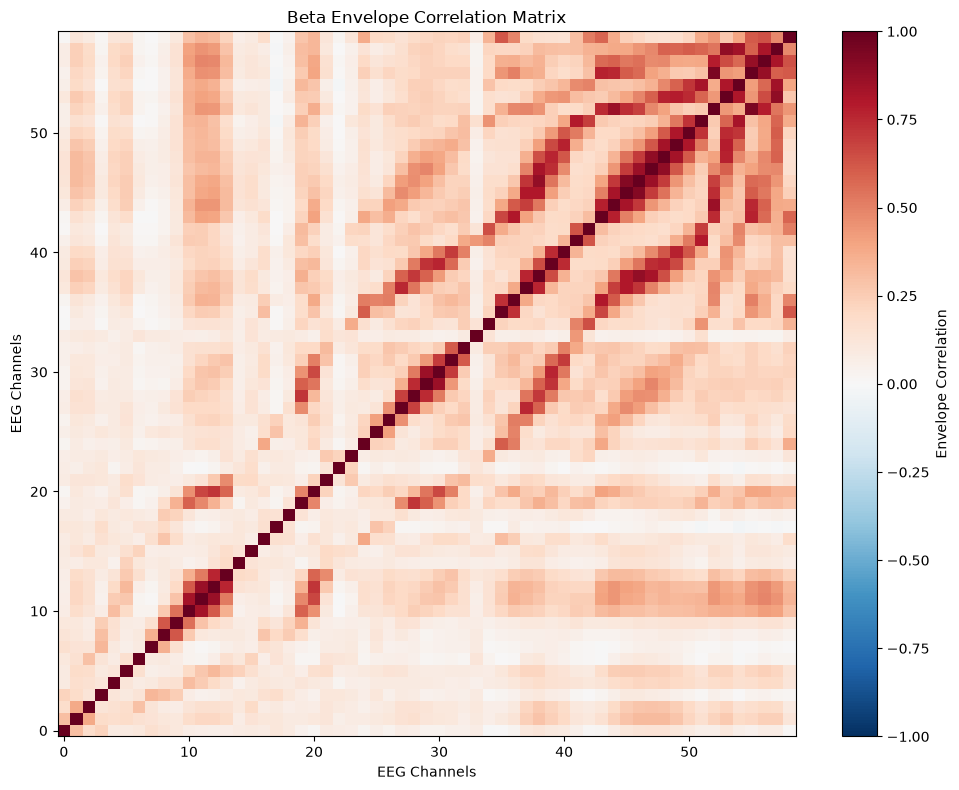

In [182]:
plt.figure(figsize=(10, 8))

plt.imshow(
    envelope_corr_matrix,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    origin="lower",
    aspect="auto"
)

plt.colorbar(label="Envelope Correlation")
plt.xlabel("EEG Channels")
plt.ylabel("EEG Channels")
plt.title("Beta Envelope Correlation Matrix")
plt.tight_layout()
plt.show()

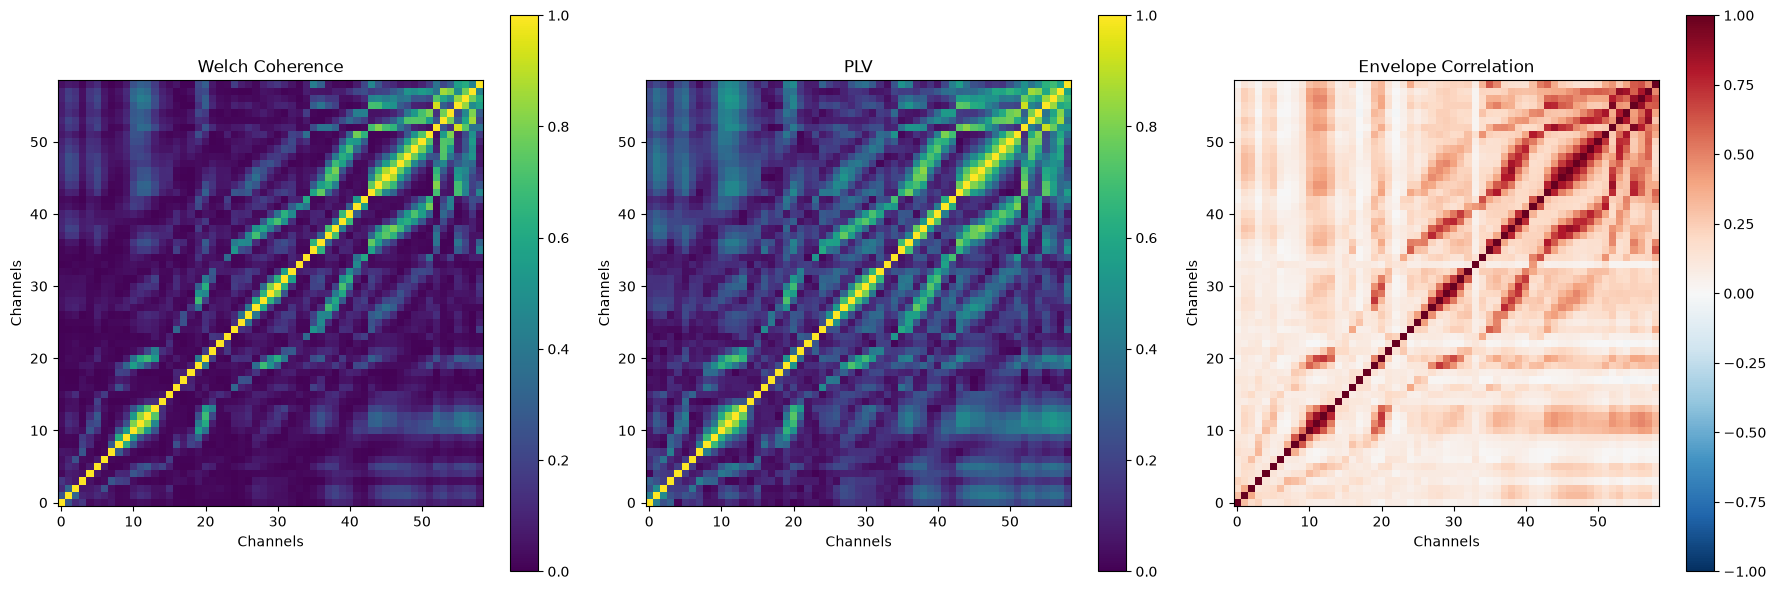

In [184]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

im1 = axes[0].imshow(
    coherence_matrix_welch,
    cmap="viridis",
    vmin=0,
    vmax=1,
    origin="lower"
)
axes[0].set_title("Welch Coherence")
axes[0].set_xlabel("Channels")
axes[0].set_ylabel("Channels")
plt.colorbar(im1, ax=axes[0])

im2 = axes[1].imshow(
    plv_matrix,
    cmap="viridis",
    vmin=0,
    vmax=1,
    origin="lower"
)
axes[1].set_title("PLV")
axes[1].set_xlabel("Channels")
axes[1].set_ylabel("Channels")
plt.colorbar(im2, ax=axes[1])

im3 = axes[2].imshow(
    envelope_corr_matrix,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    origin="lower"
)
axes[2].set_title("Envelope Correlation")
axes[2].set_xlabel("Channels")
axes[2].set_ylabel("Channels")
plt.colorbar(im3, ax=axes[2])

plt.tight_layout()
plt.show()

In [185]:
upper_values = plv_matrix[np.triu_indices(n_channels, k=1)]

print("Minimum PLV:", np.min(upper_values))
print("Maximum PLV:", np.max(upper_values))
print("Mean PLV:", np.mean(upper_values))
print("Median PLV:", np.median(upper_values))

print("\nPercentiles:")
print(np.percentile(upper_values, [25, 50, 75, 90]))

Minimum PLV: 0.006257679017412027
Maximum PLV: 0.9218320665719117
Mean PLV: 0.2232036468224155
Median PLV: 0.17838352492963658

Percentiles:
[0.09129213 0.17838352 0.29942308 0.45788371]


In [186]:
channel_1_index = eeg_names_all.index("EEG 001")
channel_2_index = eeg_names_all.index("EEG 002")

beta_pair = beta_data[[channel_1_index, channel_2_index], :]

beta_cov_matrix = np.cov(beta_pair)
beta_corr_matrix = np.corrcoef(beta_pair)

print("Beta-band Covariance Matrix:")
print(beta_cov_matrix)

print("\nBeta-band Correlation Matrix:")
print(beta_corr_matrix)

print("\nBeta Covariance (EEG 001 - EEG 002):", beta_cov_matrix[0, 1])
print("Beta Correlation (EEG 001 - EEG 002):", beta_corr_matrix[0, 1])

Beta-band Covariance Matrix:
[[1.72803083e-11 5.44400184e-12]
 [5.44400184e-12 6.63447190e-12]]

Beta-band Correlation Matrix:
[[1.         0.50843957]
 [0.50843957 1.        ]]

Beta Covariance (EEG 001 - EEG 002): 5.444001842543513e-12
Beta Correlation (EEG 001 - EEG 002): 0.5084395677821446


In [187]:
threshold = 0.30

adjacency_matrix = np.where(
    plv_matrix >= threshold,
    plv_matrix,
    0
)

np.fill_diagonal(adjacency_matrix, 0)

print("Adjacency matrix shape:", adjacency_matrix.shape)
print("Number of retained connections:", np.count_nonzero(adjacency_matrix) // 2)
print("Network density:", np.count_nonzero(adjacency_matrix) / (n_channels * (n_channels - 1)))

Adjacency matrix shape: (59, 59)
Number of retained connections: 427
Network density: 0.24956165984804207


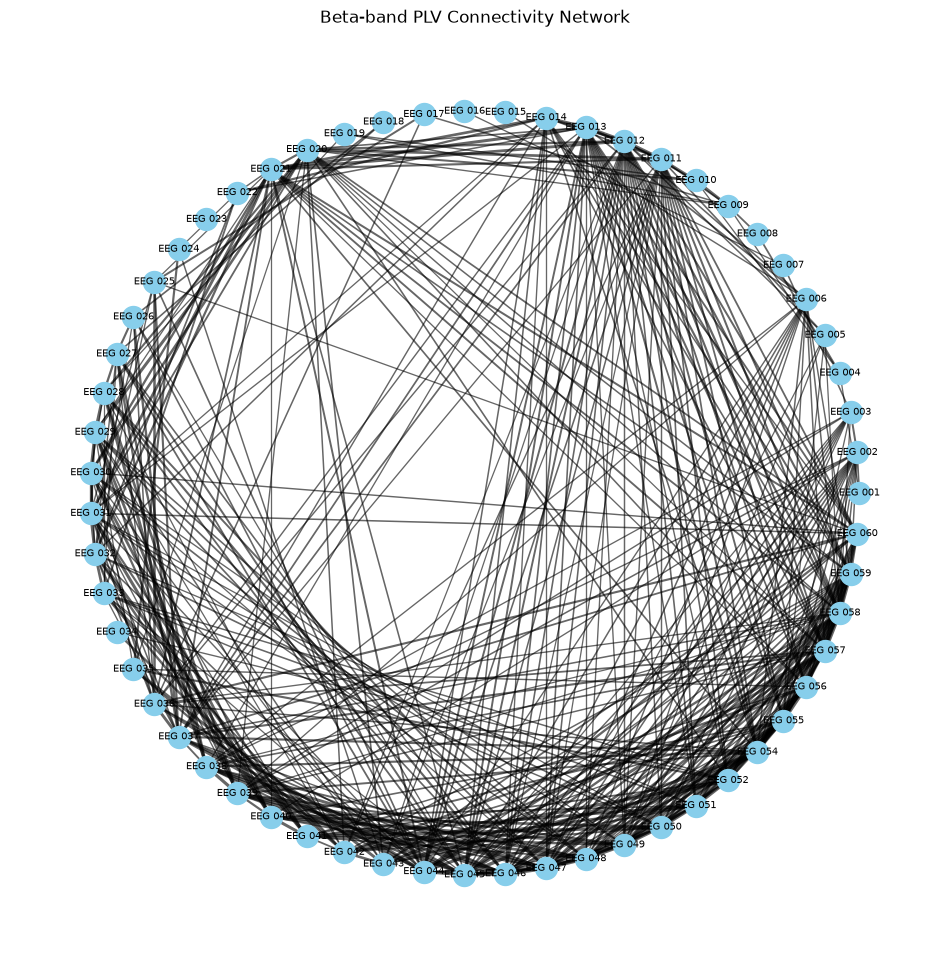

In [188]:
G = nx.from_numpy_array(adjacency_matrix)

mapping = {i: eeg_names_all[i] for i in range(n_channels)}
G = nx.relabel_nodes(G, mapping)

pos = nx.circular_layout(G)

edge_widths = [
    G[u][v]["weight"] * 3
    for u, v in G.edges()
]

plt.figure(figsize=(12, 12))

nx.draw_networkx_nodes(
    G, pos,
    node_size=250,
    node_color="skyblue"
)

nx.draw_networkx_edges(
    G, pos,
    width=edge_widths,
    alpha=0.6
)

nx.draw_networkx_labels(
    G, pos,
    font_size=7
)

plt.title("Beta-band PLV Connectivity Network")
plt.axis("off")
plt.show()

In [191]:
degree_values = np.sum(adjacency_matrix > 0, axis=1)

degree_ranking = sorted(
    zip(eeg_names_all, degree_values),
    key=lambda x: x[1],
    reverse=True
)

print("Channels ranked by Degree:\n")

for channel, degree in degree_ranking:
    print(f"{channel}: {degree} connections")

Channels ranked by Degree:

EEG 058: 29 connections
EEG 012: 28 connections
EEG 011: 26 connections
EEG 013: 26 connections
EEG 045: 26 connections
EEG 047: 26 connections
EEG 049: 25 connections
EEG 059: 25 connections
EEG 048: 24 connections
EEG 055: 24 connections
EEG 057: 24 connections
EEG 044: 23 connections
EEG 046: 23 connections
EEG 054: 23 connections
EEG 021: 22 connections
EEG 037: 21 connections
EEG 056: 21 connections
EEG 060: 21 connections
EEG 020: 20 connections
EEG 050: 19 connections
EEG 002: 18 connections
EEG 031: 18 connections
EEG 039: 18 connections
EEG 051: 18 connections
EEG 052: 18 connections
EEG 014: 17 connections
EEG 036: 17 connections
EEG 038: 17 connections
EEG 006: 16 connections
EEG 032: 16 connections
EEG 042: 16 connections
EEG 030: 15 connections
EEG 029: 14 connections
EEG 040: 14 connections
EEG 043: 14 connections
EEG 041: 13 connections
EEG 003: 12 connections
EEG 028: 12 connections
EEG 033: 12 connections
EEG 027: 11 connections
EEG 025: 8 c